# Интерполяция и подбор параметров / 插值与参数拟合

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#E07A25", "#2B8A6E", "#A64B78"]),
})
from scipy.interpolate import CubicSpline

## 1. Исходные данные / 原始数据
По пяти точкам построим линейную интерполяцию, кубический сплайн и линейную модель.

用五个数据点分别构造线性插值、三次样条和线性拟合。

In [2]:
x = np.array([0., 1., 2., 3., 4.])
y = np.array([0.2, 1.1, 1.8, 3.2, 3.9])
x_new = np.linspace(0, 4, 200)
print(np.column_stack((x, y)))

[[0.  0.2]
 [1.  1.1]
 [2.  1.8]
 [3.  3.2]
 [4.  3.9]]


## 2. Линейная интерполяция / 线性插值
`np.interp` соединяет соседние точки отрезками. Значения `x` должны быть упорядочены по возрастанию.

`np.interp` 用线段连接相邻数据点，`x` 必须按递增顺序排列。

In [3]:
y_lin = np.interp(x_new, x, y)
y_at_15 = np.interp(1.5, x, y)
print("y(1.5):", y_at_15)

y(1.5): 1.4500000000000002


## 3. Кубический сплайн / 三次样条
`CubicSpline` строит кусочно-кубическую функцию, проходящую через узлы, с непрерывными первой и второй производными. Здесь используем граничные условия по умолчанию.

`CubicSpline` 构造经过数据点的分段三次函数，其一阶、二阶导数连续。本例使用默认边界条件。

In [4]:
spline = CubicSpline(x, y)
y_spline = spline(x_new)
print("Сплайн / 样条 y(1.5):", spline(1.5))
print("Отклонение в узлах / 节点偏差:", spline(x) - y)

Сплайн / 样条 y(1.5): 1.3828125
Отклонение в узлах / 节点偏差: [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
 -4.4408921e-16]


## 4. Линейная модель / 线性模型
Подберём коэффициенты $y\approx ax+b$ методом наименьших квадратов. Прямая не обязана проходить через все точки.

用最小二乘法拟合 $y\approx ax+b$。拟合直线不要求经过所有数据点。

In [5]:
a, b = np.polyfit(x, y, 1)
y_fit = a * x_new + b
fit_residual = y - (a*x + b)
print(f"a = {a:.4f}, b = {b:.4f}")
print("Остатки / 拟合残差:", fit_residual)
print("RMSE:", np.sqrt(np.mean(fit_residual**2)))

a = 0.9500, b = 0.1400
Остатки / 拟合残差: [ 0.06  0.01 -0.24  0.21 -0.04]
RMSE: 0.14628738838327807


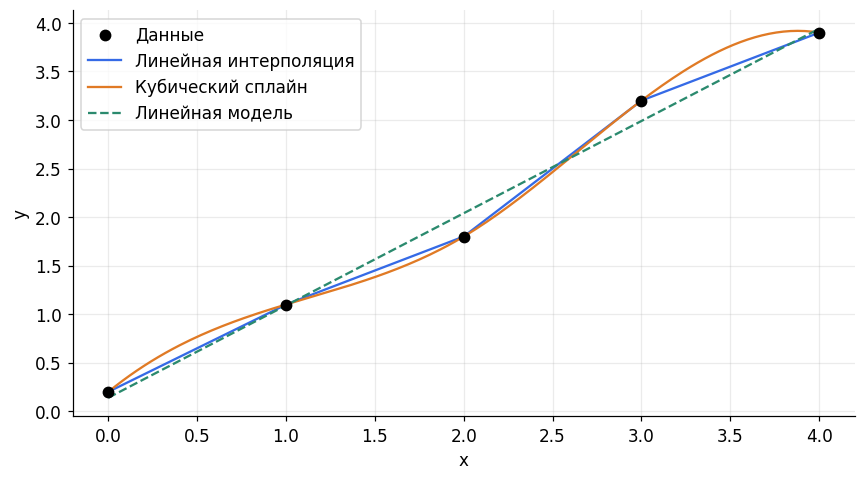

In [6]:
fig, ax = plt.subplots()
ax.scatter(x, y, color="black", s=45, label="Данные", zorder=4)
ax.plot(x_new, y_lin, label="Линейная интерполяция")
ax.plot(x_new, y_spline, label="Кубический сплайн")
ax.plot(x_new, y_fit, "--", label="Линейная модель")
ax.set(xlabel="x", ylabel="y")
ax.legend()
fig.tight_layout()
plt.show()

## 5. Отклонения в узлах / 数据点处的偏差
Интерполяция воспроизводит значения в узлах. Для линейной модели покажем разность «данные минус модель».

插值在节点处重现原数据。对线性拟合，绘制“数据减去模型值”的残差。

Линейная интерполяция / 线性插值: [0. 0. 0. 0. 0.]
Кубический сплайн / 三次样条: [ 0.0000000e+00  0.0000000e+00  0.0000000e+00  0.0000000e+00
 -4.4408921e-16]


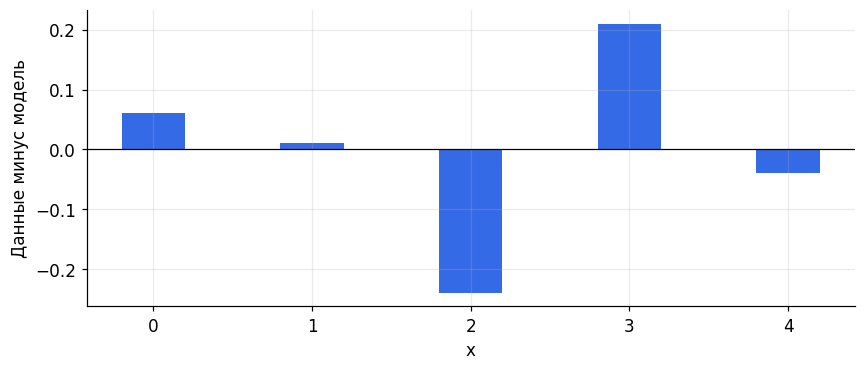

In [7]:
print("Линейная интерполяция / 线性插值:", np.interp(x, x, y) - y)
print("Кубический сплайн / 三次样条:", spline(x) - y)
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(x, fit_residual, width=0.4)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(xlabel="x", ylabel="Данные минус модель", xticks=x)
fig.tight_layout()
plt.show()

## 6. Температурные данные / 温度数据
Оценим температуру в точке `x = 1.5` и сравним три способа описания температурного профиля. Для физического примера принимаем координату в метрах, температуру в кельвинах.

估计 `x = 1.5` 处的温度，并比较三种温度分布表示方法。本物理示例约定位置单位为米，温度单位为开尔文。

In [8]:
x_T = np.array([0., 1., 2., 3., 4.])
T = np.array([300., 315., 327., 346., 358.])
x_T_dense = np.linspace(0, 4, 200)
T_linear = np.interp(x_T_dense, x_T, T)
T_spline = CubicSpline(x_T, T)
a_T, b_T = np.polyfit(x_T, T, 1)
T_fit = a_T*x_T_dense + b_T
T_at_15 = np.interp(1.5, x_T, T)
print("Линейная интерполяция / 线性插值 T(1.5), K:", T_at_15)
print("Сплайн / 样条 T(1.5), K:", T_spline(1.5))
print(f"Модель / 拟合模型: T = {a_T:.3f} x + {b_T:.3f}")

Линейная интерполяция / 线性插值 T(1.5), K: 321.0
Сплайн / 样条 T(1.5), K: 320.375
Модель / 拟合模型: T = 14.700 x + 299.800


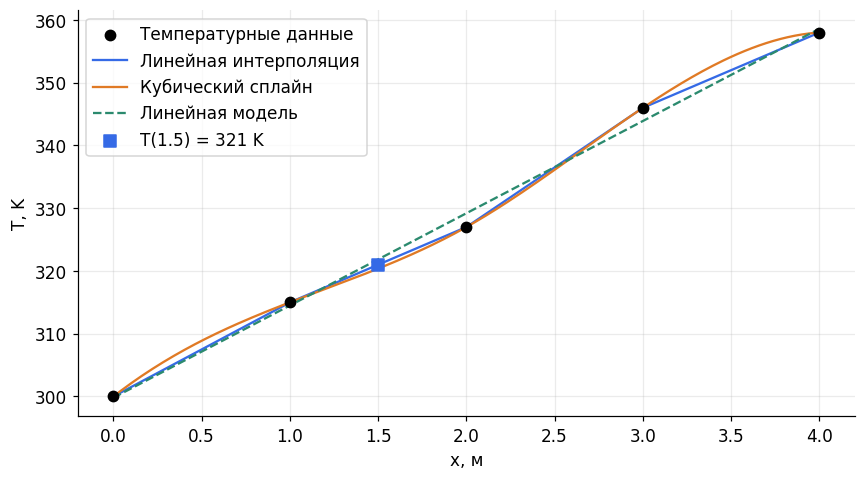

In [9]:
fig, ax = plt.subplots()
ax.scatter(x_T, T, color="black", s=45, label="Температурные данные", zorder=4)
ax.plot(x_T_dense, T_linear, label="Линейная интерполяция")
ax.plot(x_T_dense, T_spline(x_T_dense), label="Кубический сплайн")
ax.plot(x_T_dense, T_fit, "--", label="Линейная модель")
ax.scatter([1.5], [T_at_15], marker="s", s=60, label="T(1.5) = 321 K", zorder=5)
ax.set(xlabel="x, м", ylabel="T, K")
ax.legend()
fig.tight_layout()
plt.show()

Измените одно измерение и повторите расчёт. Интерполяция снова пройдёт через изменённую точку, а коэффициенты линейной модели изменятся по всему набору данных. Точное прохождение через измерения само по себе не означает более точного описания физического процесса.

修改一个测量值后重新运行：插值会再次经过修改后的点，而线性模型会根据整组数据重新确定系数。准确穿过测量点，并不一定意味着更准确地描述真实物理过程。